# House Prices — Part B: Exploration and data preparation

In this notebook I explore the Kaggle House Prices data, clean it, create a few new features and save
the processed datasets that `02_Models.ipynb` uses.

## B1. First look at the data

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

raw_dir = Path("../data/raw")
figures_dir = Path("../results/figures")
processed_dir = Path("../data/processed")
figures_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(raw_dir / "train.csv")
test = pd.read_csv(raw_dir / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (1460, 81)
Test: (1459, 80)


In [2]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
numeric_columns = train.select_dtypes(include="number").columns
text_columns = train.select_dtypes(exclude="number").columns

print("Numeric columns:", len(numeric_columns))
print("Text (categorical) columns:", len(text_columns))
print("Columns only in train:", set(train.columns) - set(test.columns))

Numeric columns: 38
Text (categorical) columns: 43
Columns only in train: {'SalePrice'}


In [4]:
train[["LotArea", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars", "SalePrice"]].describe().round(1)

,LotArea,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,SalePrice
count,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0,1460.0
mean,10516.8,1515.5,6.1,1971.3,1057.4,1.8,180921.2
std,9981.3,525.5,1.4,30.2,438.7,0.7,79442.5
min,1300.0,334.0,1.0,1872.0,0.0,0.0,34900.0
25%,7553.5,1129.5,5.0,1954.0,795.8,1.0,129975.0
50%,9478.5,1464.0,6.0,1973.0,991.5,2.0,163000.0
75%,11601.5,1776.8,7.0,2000.0,1298.2,2.0,214000.0
max,215245.0,5642.0,10.0,2010.0,6110.0,4.0,755000.0


- The training set has 1,460 houses and the test set 1,459. Each house has 79 features plus `Id`; only the
  training set has the target `SalePrice`.
- 38 columns are numeric and 43 are text (categorical), so the text columns must be encoded before modelling.
- Sizes vary a lot: `LotArea` goes from 1,300 to 215,245 sq ft, and the price from \$34,900 to \$755,000.

## B2. Target distribution

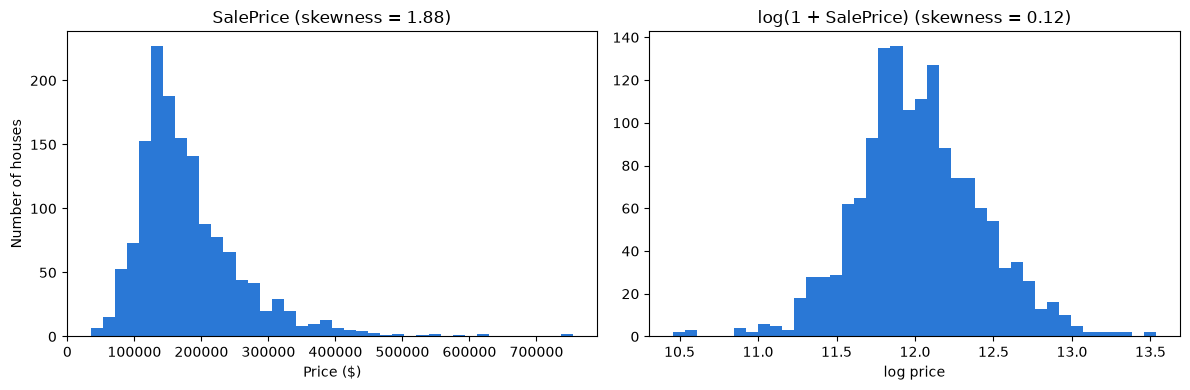

Median price: $163,000
Cheapest: $34,900, most expensive: $755,000


In [5]:
prices = train["SalePrice"]
log_prices = np.log1p(prices)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(prices, bins=40, color="#2a78d6")
axes[0].set_title(f"SalePrice (skewness = {prices.skew():.2f})")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of houses")

axes[1].hist(log_prices, bins=40, color="#2a78d6")
axes[1].set_title(f"log(1 + SalePrice) (skewness = {log_prices.skew():.2f})")
axes[1].set_xlabel("log price")

plt.tight_layout()
fig.savefig(figures_dir / "01_target_distribution.png", dpi=120)
plt.show()

print(f"Median price: ${prices.median():,.0f}")
print(f"Cheapest: ${prices.min():,.0f}, most expensive: ${prices.max():,.0f}")

`SalePrice` is **right-skewed** (skewness 1.88): most houses cost between \$100k and \$250k, and a few
expensive houses form a long tail. After `log(1 + SalePrice)` the distribution is almost symmetric
(skewness 0.12).

I will train the models on the log price because:
1. the Kaggle metric is the RMSE of the logarithms, so a 10% error counts the same for a cheap and an expensive house;
2. the expensive houses do not dominate the training of linear models.

Predictions are converted back to dollars with `np.expm1`.

## B3. Missing values

In [6]:
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "test_missing": test.isna().sum(),
})
missing = missing[missing.sum(axis=1) > 0]
missing["train_percent"] = (100 * missing["train_missing"] / len(train)).round(1)
missing = missing.sort_values("train_missing", ascending=False)

print("Columns with missing values:", len(missing))
missing

Columns with missing values: 34


,train_missing,test_missing,train_percent
PoolQC,1453,1456.0,99.5
MiscFeature,1406,1408.0,96.3
Alley,1369,1352.0,93.8
Fence,1179,1169.0,80.8
MasVnrType,872,894.0,59.7
FireplaceQu,690,730.0,47.3
LotFrontage,259,227.0,17.7
GarageYrBlt,81,78.0,5.5
GarageQual,81,78.0,5.5
GarageFinish,81,78.0,5.5


According to `data_description.txt`, in most of these columns an empty value does not mean "unknown".
It means that the house **does not have** the feature: no pool, no alley, no fence, no garage, no basement, and so on.
So I fill them with the category `"None"`, and the related areas and counts with `0`.

In [7]:
none_columns = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
zero_columns = [
    "MasVnrArea", "GarageCars", "GarageArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
]

train_clean = train.copy()
test_clean = test.copy()

for data in (train_clean, test_clean):
    data[none_columns] = data[none_columns].fillna("None")
    data[zero_columns] = data[zero_columns].fillna(0)

`LotFrontage` (length of the street in front of the lot) is really unknown for 259 training houses.
Houses in the same neighborhood have similar lots, so I fill it with the **median of the neighborhood**,
computed only on the training data. I also keep a 0/1 column saying that the value was missing.

In [8]:
neighborhood_median = train.groupby("Neighborhood")["LotFrontage"].median()
overall_median = train["LotFrontage"].median()

for data in (train_clean, test_clean):
    data["LotFrontageMissing"] = data["LotFrontage"].isna().astype(int)
    filled = data["Neighborhood"].map(neighborhood_median).fillna(overall_median)
    data["LotFrontage"] = data["LotFrontage"].fillna(filled)

train_clean[["Neighborhood", "LotFrontage", "LotFrontageMissing"]].head()

,Neighborhood,LotFrontage,LotFrontageMissing
0,CollgCr,65.0,0
1,Veenker,80.0,0
2,CollgCr,68.0,0
3,Crawfor,60.0,0
4,NoRidge,84.0,0


`GarageYrBlt` is empty for every house without a garage, and for the other houses it is almost the same as
`YearBuilt`. I will drop it in B7, so I do not fill it.

The few values that are still missing are mostly in the test set (for example `MSZoning`, `KitchenQual`, `SaleType`).
I fill them with the **most frequent value (text) or the median (numbers) of the training set**.

In [9]:
for column in test_clean.columns:
    if train_clean[column].isna().any() or test_clean[column].isna().any():
        if pd.api.types.is_numeric_dtype(train_clean[column]):
            value = train_clean[column].median()
        else:
            value = train_clean[column].mode()[0]
        print(f"{column:12s} train: {train_clean[column].isna().sum()}  test: {test_clean[column].isna().sum()}  -> {value}")
        train_clean[column] = train_clean[column].fillna(value)
        test_clean[column] = test_clean[column].fillna(value)

MSZoning     train: 0  test: 4  -> RL
Utilities    train: 0  test: 2  -> AllPub
Exterior1st  train: 0  test: 1  -> VinylSd
Exterior2nd  train: 0  test: 1  -> VinylSd
Electrical   train: 1  test: 0  -> SBrkr
KitchenQual  train: 0  test: 1  -> TA
Functional   train: 0  test: 2  -> Typ
GarageYrBlt  train: 81  test: 78  -> 1980.0
SaleType     train: 0  test: 1  -> WD


## B4. Feature visualizations

In [10]:
correlations = train_clean.select_dtypes(include="number").corr()["SalePrice"]
correlations = correlations.drop(["SalePrice", "Id"]).sort_values(ascending=False)
correlations.head(10).round(3)

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

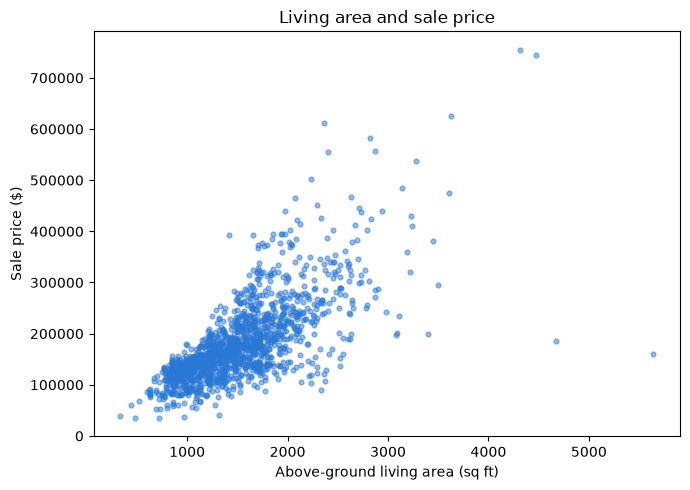

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train_clean["GrLivArea"], train_clean["SalePrice"], s=12, alpha=0.5, color="#2a78d6")
ax.set_title("Living area and sale price")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
plt.tight_layout()
fig.savefig(figures_dir / "02_living_area_vs_price.png", dpi=120)
plt.show()

Price grows almost linearly with living area, and the spread grows for bigger houses. Two houses on the right
(more than 4,500 sq ft) are clearly far below the trend; I look at them in B5.

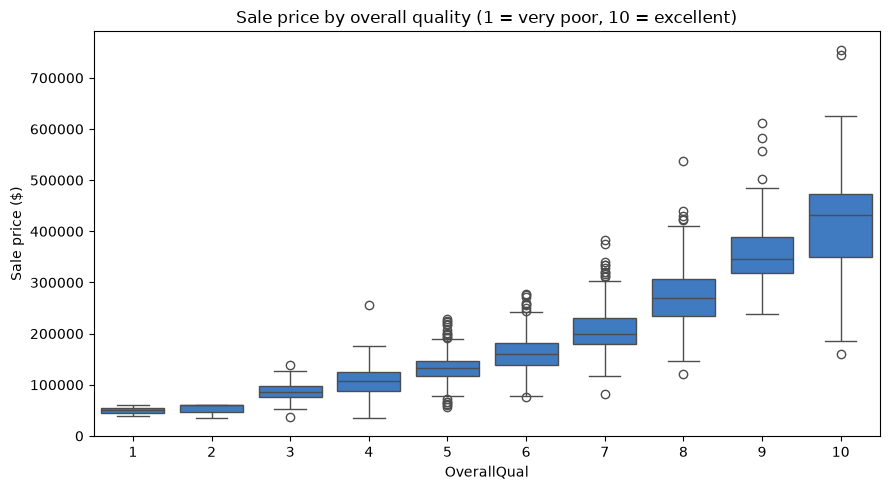

OverallQual
1      50150.0
2      60000.0
3      86250.0
4     108000.0
5     133000.0
6     160000.0
7     200141.0
8     269750.0
9     345000.0
10    432390.0
Name: SalePrice, dtype: float64

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=train_clean, x="OverallQual", y="SalePrice", color="#2a78d6", ax=ax)
ax.set_title("Sale price by overall quality (1 = very poor, 10 = excellent)")
ax.set_xlabel("OverallQual")
ax.set_ylabel("Sale price ($)")
plt.tight_layout()
fig.savefig(figures_dir / "03_quality_vs_price.png", dpi=120)
plt.show()

train_clean.groupby("OverallQual")["SalePrice"].median()

`OverallQual` is the strongest single predictor (correlation 0.79). The median price goes from about \$50k
at quality 1 to about \$430k at quality 10, and it grows faster at the high-quality levels.

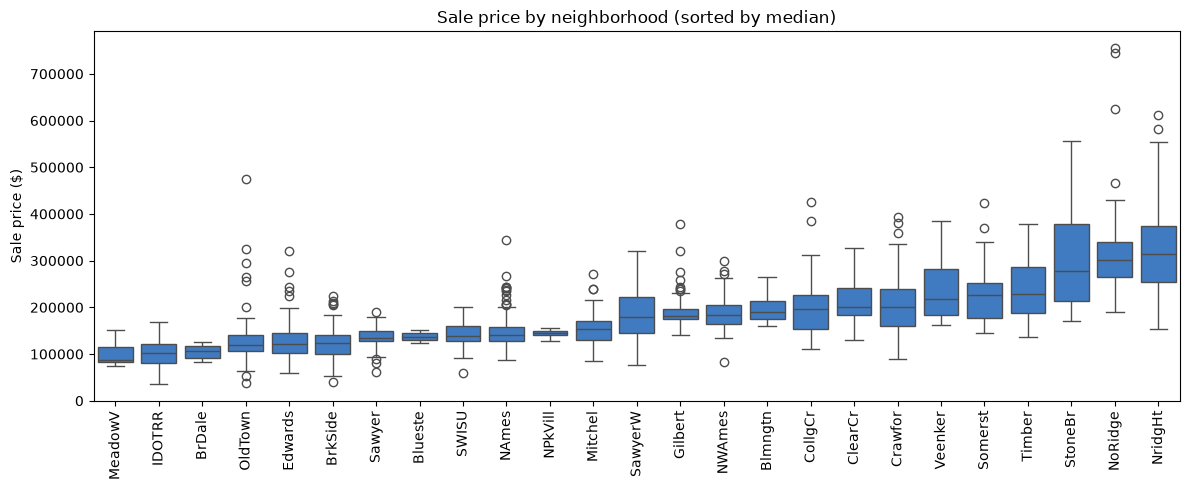

In [13]:
order = train_clean.groupby("Neighborhood")["SalePrice"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=train_clean, x="Neighborhood", y="SalePrice", order=order, color="#2a78d6", ax=ax)
ax.set_title("Sale price by neighborhood (sorted by median)")
ax.set_xlabel("")
ax.set_ylabel("Sale price ($)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
fig.savefig(figures_dir / "04_neighborhood_prices.png", dpi=120)
plt.show()

Location matters a lot: the median price in the most expensive neighborhoods (NridgHt, NoRidge, StoneBr)
is about 3 times the median in the cheapest ones (MeadowV, IDOTRR, BrDale). `Neighborhood` is a text column,
so it will be one-hot encoded.

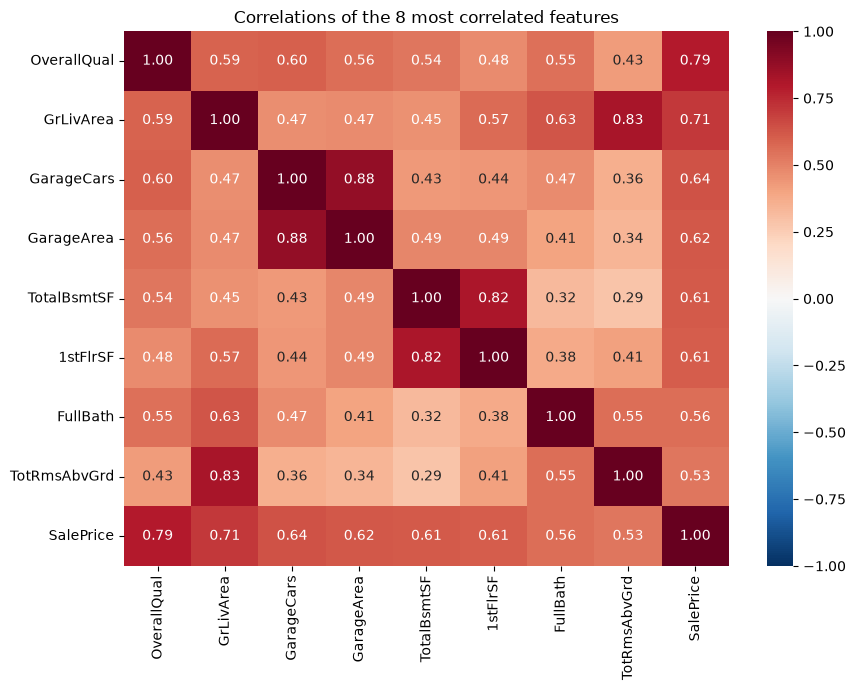

In [14]:
top_columns = list(correlations.head(8).index) + ["SalePrice"]

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_clean[top_columns].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlations of the 8 most correlated features")
plt.tight_layout()
fig.savefig(figures_dir / "05_correlations.png", dpi=120)
plt.show()

The heatmap shows that some strong features are almost duplicates of each other:
`GarageCars`/`GarageArea` (0.88) and `TotalBsmtSF`/`1stFlrSF` (0.82). Such correlated features are a
problem for plain linear regression, so I will also try **Ridge and Lasso**, which handle them with regularization.

## B5. Outliers

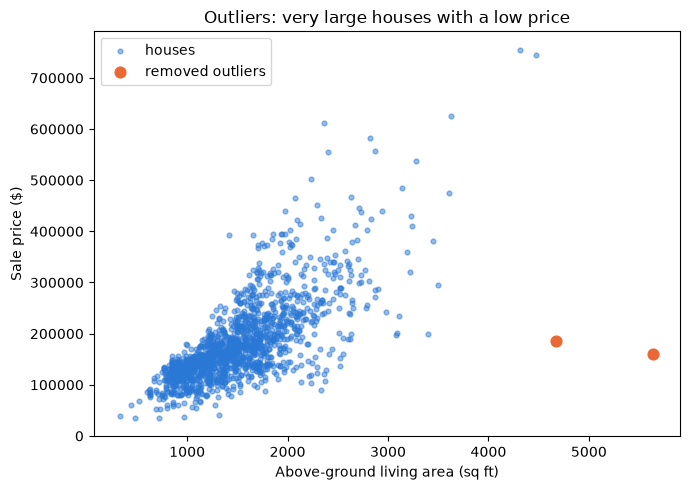

,Id,GrLivArea,OverallQual,SaleCondition,SalePrice
523,524,4676,10,Partial,184750
691,692,4316,10,Normal,755000
1182,1183,4476,10,Abnorml,745000
1298,1299,5642,10,Partial,160000


In [15]:
is_outlier = (train_clean["GrLivArea"] > 4000) & (train_clean["SalePrice"] < 300000)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train_clean["GrLivArea"], train_clean["SalePrice"], s=12, alpha=0.5, color="#2a78d6", label="houses")
ax.scatter(train_clean.loc[is_outlier, "GrLivArea"], train_clean.loc[is_outlier, "SalePrice"],
           s=60, color="#eb6834", label="removed outliers")
ax.set_title("Outliers: very large houses with a low price")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.legend()
plt.tight_layout()
fig.savefig(figures_dir / "06_outliers.png", dpi=120)
plt.show()

train_clean.loc[train_clean["GrLivArea"] > 4000,
                ["Id", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice"]]

There are four houses with more than 4,000 sq ft of living area:
- Ids **692** and **1183** are very expensive (\$755k and \$745k), which follows the trend, so I keep them.
- Ids **524** and **1299** are the largest and best-quality houses, but sold for only \$185k and \$160k.
  Both are `Partial` sales (houses that were not finished when sold), so the price does not reflect the value of
  the house. They would pull the regression line down for all big houses, so **I remove these 2 houses
  from the training set**. The author of the dataset (De Cock, 2011) also recommends removing houses
  larger than 4,000 sq ft for this reason.

I do not remove any other rows, and I never remove rows from the test set.

In [16]:
train_clean = train_clean[~is_outlier].reset_index(drop=True)
print("Training houses after removing outliers:", len(train_clean))
print("Test houses (never removed):", len(test_clean))

Training houses after removing outliers: 1458
Test houses (never removed): 1459


## B6. New features

I create six features that describe the house in a more direct way than the original columns:

| Feature | Meaning |
|---|---|
| `TotalSF` | basement + 1st floor + 2nd floor area |
| `HouseAge` | years between construction and sale |
| `RemodAge` | years between the last remodeling and sale |
| `TotalBathrooms` | full baths + half baths × 0.5 (including the basement) |
| `TotalPorchSF` | sum of all porch areas |
| `HasGarage` | 1 if the house has a garage |

In [17]:
for data in (train_clean, test_clean):
    data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
    data["HouseAge"] = (data["YrSold"] - data["YearBuilt"]).clip(lower=0)
    data["RemodAge"] = (data["YrSold"] - data["YearRemodAdd"]).clip(lower=0)
    data["TotalBathrooms"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                              + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])
    data["TotalPorchSF"] = (data["OpenPorchSF"] + data["EnclosedPorch"]
                            + data["3SsnPorch"] + data["ScreenPorch"])
    data["HasGarage"] = (data["GarageArea"] > 0).astype(int)

new_features = ["TotalSF", "HouseAge", "RemodAge", "TotalBathrooms", "TotalPorchSF", "HasGarage"]
train_clean[new_features].head()

,TotalSF,HouseAge,RemodAge,TotalBathrooms,TotalPorchSF,HasGarage
0,2566,5,5,3.5,61,1
1,2524,31,31,2.5,0,1
2,2706,7,6,3.5,42,1
3,2473,91,36,2.0,307,1
4,3343,8,8,3.5,84,1


In [18]:
log_price = np.log1p(train_clean["SalePrice"])
compare = {
    "TotalSF (new)": "TotalSF", "GrLivArea": "GrLivArea", "TotalBsmtSF": "TotalBsmtSF",
    "HouseAge (new)": "HouseAge", "YearBuilt": "YearBuilt",
    "TotalBathrooms (new)": "TotalBathrooms", "FullBath": "FullBath",
    "TotalPorchSF (new)": "TotalPorchSF", "OpenPorchSF": "OpenPorchSF",
    "HasGarage (new)": "HasGarage",
}
pd.Series({name: train_clean[column].corr(log_price) for name, column in compare.items()},
          name="correlation with log price").round(3)

TotalSF (new)           0.825
GrLivArea               0.725
TotalBsmtSF             0.648
HouseAge (new)         -0.588
YearBuilt               0.587
TotalBathrooms (new)    0.677
FullBath                0.596
TotalPorchSF (new)      0.196
OpenPorchSF             0.325
HasGarage (new)         0.323
Name: correlation with log price, dtype: float64

`TotalSF` (0.825) is more correlated with the log price than any single area column, and `TotalBathrooms`
(0.677) is better than `FullBath` (0.596). `HouseAge` contains the same information as `YearBuilt`
(the sign is negative: older houses are cheaper). `TotalPorchSF` turned out to be weaker than `OpenPorchSF`
alone, so not every combination helps. The real test is the cross-validation in `02_Models.ipynb`.

## B7. Select and encode features

In [10]:
train_features = train_clean.drop(columns=["Id", "SalePrice"])
test_features = test_clean.drop(columns=["Id"])

train_encoded = pd.get_dummies(train_features, dtype=int)
test_encoded = pd.get_dummies(test_clean, dtype=int)

test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0)

print("Train features:", train_encoded.shape)
print("Test features:", test_encoded.shape)
print("Same columns:", train_encoded.columns.equals(test_encoded.columns))

Train features: (1460, 303)
Test features: (1459, 303)
Same columns: True


In [11]:
processed_dir = raw_dir.parent / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

train_processed = pd.concat([train_clean[["Id", "SalePrice"]], train_encoded], axis=1)
test_processed = pd.concat([test_clean[["Id"]], test_encoded], axis=1)

train_processed.to_csv(processed_dir / "train_processed.csv", index=False)
test_processed.to_csv(processed_dir / "test_processed.csv", index=False)